## Setup: Running This Notebook From Scratch

Follow these steps in a terminal, inside this project's folder, before opening the notebook.
Make sure `heart_disease_combined.csv` (the dataset) is in the same folder as this notebook.

### 1. Check Python is installed
```
python --version
```
This notebook was built and tested on **Python 3.13**. Python 3.10 or newer should work.

### 2. Create a virtual environment
A virtual environment keeps this project's packages separate from the rest of your system.

**Windows (Command Prompt / PowerShell):**
```
python -m venv venv
```

**macOS / Linux:**
```
python3 -m venv venv
```

### 3. Activate the virtual environment
You must do this every time you open a new terminal to work on this project.

**Windows (Command Prompt):**
```
venv\Scripts\activate.bat
```

**Windows (PowerShell):**
```
venv\Scripts\Activate.ps1
```
*(If PowerShell blocks this with an execution-policy error, run once: `Set-ExecutionPolicy -Scope CurrentUser RemoteSigned`)*

**macOS / Linux:**
```
source venv/bin/activate
```

Your terminal prompt should now show `(venv)` at the start of the line.

### 4. Install the required packages
This project ships a `requirements.txt` file listing the packages it needs.
```
pip install -r requirements.txt
```

### 5. Register the virtual environment as a Jupyter kernel (recommended)
```
python -m ipykernel install --user --name=heart-venv --display-name "Python (heart-venv)"
```
When you open the notebook, make sure **Kernel -> Change Kernel -> Python (heart-venv)** is selected, so it uses the packages you just installed.

### 6. Launch Jupyter Notebook
```
jupyter notebook
```
This opens Jupyter in your browser. Click this `.ipynb` file to open it, then run all cells from the top (**Kernel -> Restart & Run All**).

### 7. When you're done
Deactivate the virtual environment with:
```
deactivate
```

---

# Heart Disease Prediction System

## Adaptation Notes (this version)
This notebook is the **Titanic Passenger Survival Prediction System** re-built for **heart disease prediction**. It keeps the same 10-step teaching flow (Label Encoding + Support Vector Classifier, Training / Testing / Application / Feedback phases, evaluation metrics, and web deployment).

**Constraint followed:** the model uses exactly **4 input attributes** selected from the heart disease dataset.

What changed compared with the Titanic notebook, and why:

| Area | Titanic notebook | This notebook | Reason |
| ---- | ---------------- | ------------- | ------ |
| Data | 100-row, already clean sample | 920-row combined UCI heart disease data (Cleveland, Hungarian, VA, Switzerland) | Real data is messy |
| Step 3.2 Pre-processing | "Nothing to do" | Replace `?` placeholders, convert text to numbers, drop incomplete rows (920 rows become 865) | The raw file stores missing values as `?` |
| Step 4 Feature Extraction | "Nothing to do" | Select 4 attributes (age, gender, chest pain type, exercise-induced angina), keep age as a real number, convert `sex`, `cp`, `exang` and `num` into readable labels | Exact age carries more information than coarse bands |
| Step 6.1 Split | `shuffle=False` | `shuffle=True` + `stratify` | The file is ordered by hospital, so an unshuffled 20% test set would come from only one or two hospitals |
| Step 6.3 Training | Plain SVC | StandardScaler + SVC in one Pipeline | `Age` (28 to 77) is on a very different scale from the Gender code (0 or 1), the ChestPain code (0 to 3) and the ExerciseAngina code (0 or 1), so without scaling age would dominate the model |
| Output | Survived (Yes/No) | HeartDisease (Yes/No) | `num > 0` means heart disease was found |

> **Educational use only.** This model is a classroom exercise built on four coarse attributes. It is **not** a medical device and must not be used to diagnose or rule out heart disease.

## SU Meta Description
<p>
Discover the Heart Disease Prediction System, a machine learning model that uses four simple patient attributes (age, gender, chest pain type, and exercise-induced angina) to predict whether heart disease is present.
</p>

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (1) or does not (0) using four attributes (age, gender, chest pain type, and exercise-induced angina).
##### **Application** It is mainly used for learning data science, testing ML algorithms, and gaining insights into risk factors such as chest pain type, exercise-induced angina, gender and age.

##  Input and Output

###  Inputs (Features / Attributes)

| **Input Feature/Attribute**  |      **Possible Values**          | **Derived from dataset column** |
| ------------ | ---------------------------------- | ---------- |
| **Age**   | A whole number of years (28 to 77 in this data) | `age` (kept as a number) |
| **Gender**   | Male, Female                       | `sex` |
| **ChestPain** | Typical angina, Atypical angina, Non-anginal pain, Asymptomatic | `cp` |
| **ExerciseAngina** | No, Yes (chest pain brought on by exercise) | `exang` |

### Why these 4 attributes?

The dataset has 13 candidate attributes, and the constraint is to use only 4. These four are simple patient details that are easy to collect. The table shows how much of each is missing in the raw data and how often heart disease occurs in the cleaned data (865 patients):

| Attribute | Missing in raw data | Heart disease rate in cleaned data |
| --------- | ------------------- | -------------------------- |
| `age` (Age) | 0 | Under 45: 33%, 45 to 59: 54%, 60 and over: **74%** |
| `sex` (Gender) | 0 | Female 26%, Male **63%** |
| `cp` (Chest pain) | 0 | Asymptomatic **79%**, Typical angina 45%, Non-anginal pain 33%, Atypical angina 14% |
| `exang` (Exercise-induced angina) | 55 | No 36%, Yes **84%** |

Chest pain type and exercise-induced angina are the two strongest of the four. Replacing cholesterol with exercise-induced angina raised the test accuracy from about 74% to about 80%. It also keeps more patients: cholesterol had 172 impossible zeros and 30 missing values, so using it removed 202 rows (718 patients were left), while exercise angina is missing in only 55 rows (865 patients are left, from all four hospitals). Note that "Asymptomatic" (no chest pain symptoms) has the *highest* disease rate in this data: many patients whose heart disease was confirmed by tests reported no chest pain.

Attributes that were **not** used: `trestbps` (resting blood pressure) and `chol` (cholesterol: 172 impossible zeros and 30 missing) are not inputs; `ca` (611 of 920 values missing), `thal` (486 missing) and `slope` (309 missing) are too incomplete to use reliably; `thalach`, `oldpeak`, `fbs` and `restecg` would not fit the 4-attribute limit.

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------------- |
| **HeartDisease**     | Yes, No                   |

### Examples (Heart Disease Dataset)

| Age | Gender | ChestPain | ExerciseAngina | HeartDisease |
| :-: | :----: | :-------: | :------------: | :----------: |
| 63 | Male | Typical angina | No | No |
| 67 | Male | Asymptomatic | Yes | Yes |
| 67 | Male | Asymptomatic | Yes | Yes |
| 37 | Male | Non-anginal pain | No | No |
| 41 | Female | Atypical angina | No | No |

## Developer & System Information

|                                |                                                                                         |
| ------------------------------------------- | --------------------------------------------------------------------------------------------------- |
| **Developer Name**                          | *(add your name here)*                                                                              |
| **Adapted From**                            | Titanic Passenger Survival Prediction System by Mr. Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab   |
| **Program Name**                            | heart\_disease\_project                                                                           |
| **IDE**                                     | Jupyter Notebook                                                                                    |
| **Programming Language**                    | Python 3.13                                                                                         |
| **Operating System**                        | Linux                                                                                               |
| **Libraries**                               | NumPy 2.5.3, Pandas 3.0.5, Pickle (built-in), scikit-learn 1.9.1, PrettyTable 3.18.0, Matplotlib 3.11.2, Seaborn 0.13.2 |
| **Dataset**                                 | Combined UCI Heart Disease data (Cleveland, Hungarian, VA Long Beach, Switzerland), 920 rows        |
| **Date of Completion**                      | 10-Oct-2026                                                                                         |

##  Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)
  - Step 5.1: Train the Label Encoder
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Models on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
    - Step 8.5.1: Apply Model and Return Prediction to the User
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- Step 10: Deploy Your Model as a Public Web App
  - Step 10.1: Why Deploy a Model?
  - Step 10.2: Create a GitHub Account and Repository
  - Step 10.3: Write a Simple Web App
  - Step 10.4: Create a Streamlit Community Cloud Account
  - Step 10.5: Deploy Your App
  - Step 10.6: Troubleshooting Common Issues
  - Step 10.7: Share Your Live Link

## Code – Heart Disease Prediction

###  Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.
"""

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Import Pipeline (chains the scaler and the model into one saved model)
from sklearn.pipeline import Pipeline

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
This part of the code loads the heart disease dataset from a CSV file into a
pandas DataFrame. It then displays the first rows of the dataset so that students
can see the raw data being used for further processing and model training.
"""

# Read the CSV file and load it into a pandas DataFrame
# 'heart_disease_combined.csv' should be present in the working directory
raw_data = pd.read_csv("heart_disease_combined.csv")

# Print a header to indicate that raw data is being displayed
print("\n\nRaw Heart Disease Data (first 10 rows):")
print("=======================================\n")

# Configure pandas to display all columns (so nothing gets hidden with '...')
pd.set_option("display.max_columns", None)

# Print the first 10 rows (the full dataset has 920 rows)
print(raw_data.head(10))



Raw Heart Disease Data (first 10 rows):

      source   age  sex   cp trestbps   chol  fbs restecg thalach exang  \
0  cleveland  63.0  1.0  1.0    145.0  233.0  1.0     2.0   150.0   0.0   
1  cleveland  67.0  1.0  4.0    160.0  286.0  0.0     2.0   108.0   1.0   
2  cleveland  67.0  1.0  4.0    120.0  229.0  0.0     2.0   129.0   1.0   
3  cleveland  37.0  1.0  3.0    130.0  250.0  0.0     0.0   187.0   0.0   
4  cleveland  41.0  0.0  2.0    130.0  204.0  0.0     2.0   172.0   0.0   
5  cleveland  56.0  1.0  2.0    120.0  236.0  0.0     0.0   178.0   0.0   
6  cleveland  62.0  0.0  4.0    140.0  268.0  0.0     2.0   160.0   0.0   
7  cleveland  57.0  0.0  4.0    120.0  354.0  0.0     0.0   163.0   1.0   
8  cleveland  63.0  1.0  4.0    130.0  254.0  0.0     2.0   147.0   0.0   
9  cleveland  53.0  1.0  4.0    140.0  203.0  1.0     2.0   155.0   1.0   

  oldpeak slope   ca thal  num  
0     2.3   3.0  0.0  6.0    0  
1     1.5   2.0  3.0  3.0    2  
2     2.6   2.0  2.0  7.0    1  

### Step 3: Understand and Pre-process Sample Data

####  Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
3. Counting the missing values ('?') in each attribute, so we know which
   attributes are safe to use as inputs.
"""

# Print a header for clarity
print("\n\nAttributes in Raw Data:")
print("=======================\n")

# Display all column names (attributes) in the dataset
print(raw_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Raw Data:", raw_data["age"].count())
print("================================\n")

# Count the '?' placeholders (missing values) in every attribute
print("Missing values ('?') per attribute:")
print("===================================\n")
missing_counts = (raw_data.astype(str) == "?").sum()
print(missing_counts)

# Chest pain (cp) has no missing values and uses the codes 1 to 4.
# Exercise-induced angina (exang) uses 1 = yes and 0 = no, and a few values are missing.
print("\nMissing values in 'exang':", missing_counts["exang"])
print("Chest pain types (cp) in the raw data:", sorted(raw_data["cp"].astype(str).unique()))
print("Exercise angina values (exang) in the raw data:", sorted(raw_data["exang"].astype(str).unique()))



Attributes in Raw Data:

Index(['source', 'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
       'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')


Number of Instances in Raw Data: 920

Missing values ('?') per attribute:

source        0
age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalach      55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

Missing values in 'exang': 55
Chest pain types (cp) in the raw data: ['1.0', '2.0', '3.0', '4.0']
Exercise angina values (exang) in the raw data: ['0', '0.0', '1', '1.0', '?']


#### Step 3.2: Pre-process Sample Data
Unlike the Titanic sample, this data is **not** ready to use. It needs these pre-processing actions:

- Missing values are stored as the text `?`, which makes several numeric columns text columns, so `?` is replaced with a real missing value
- The 4 chosen attributes are converted to numbers
- Rows that are missing any of the 4 chosen attributes are removed (920 rows become 865; only `exang` has gaps, 55 rows)
- `num` (0 = no disease, 1-4 = disease severity) is converted to a Yes/No target, because this is a binary classification task

In [4]:
"""
Purpose of this section:
-------------------------
This part of the code cleans the raw data:
1. Replace the '?' placeholders with real missing values (NaN).
2. Convert the columns we need into numeric type.
3. Drop the rows that have a missing value in any of the 4 chosen attributes.
"""

# Work on a copy so that the raw data stays untouched
cleaned_data = raw_data.copy()

# Replace '?' placeholders with NaN (proper missing values)
cleaned_data = cleaned_data.replace("?", np.nan)

# Convert the attributes we need (and the target 'num') into numbers
for column in ["age", "sex", "cp", "exang", "num"]:
    cleaned_data[column] = pd.to_numeric(cleaned_data[column], errors="coerce")

# Remove rows with a missing value in any of the 4 chosen attributes
rows_before = len(cleaned_data)
cleaned_data = cleaned_data.dropna(subset=["age", "sex", "cp", "exang"]).reset_index(drop=True)
rows_after = len(cleaned_data)

print("\n\nPre-processing Summary:")
print("=======================\n")
print("Rows before cleaning :", rows_before)
print("Rows removed         :", rows_before - rows_after)
print("Rows after cleaning  :", rows_after)




Pre-processing Summary:

Rows before cleaning : 920
Rows removed         : 55
Rows after cleaning  : 865


#### Step 4: Feature Extraction
Only **4 input attributes** are selected from the dataset, and each one is prepared for the model (age stays a real number, gender, chest pain and exercise angina become readable categories):

- `age` becomes **Age** and is kept as a whole number of years
- `sex` becomes **Gender** (1 = Male, 0 = Female)
- `cp` becomes **ChestPain** (1 = Typical angina, 2 = Atypical angina, 3 = Non-anginal pain, 4 = Asymptomatic)
- `exang` becomes **ExerciseAngina** (1 = Yes, 0 = No)
- `num` becomes **HeartDisease** (0 = No, 1 to 4 = Yes)


In [5]:
"""
Purpose of this section:
-------------------------
This part of the code performs Feature Extraction. It selects exactly 4 input
attributes (Age, Gender, ChestPain, ExerciseAngina), keeps Age as a number,
converts Gender, ChestPain and ExerciseAngina into readable categories, creates the
output (HeartDisease), and saves the result as 'sample-data.csv' (the equivalent of
the Titanic sample data).
"""

# Keep age as a whole number (it is NOT grouped into bands)
age = cleaned_data["age"].astype(int)

# Convert the numeric codes into readable categories
gender = cleaned_data["sex"].map({1.0: "Male", 0.0: "Female"})
chest_pain = cleaned_data["cp"].map({
    1.0: "Typical angina",
    2.0: "Atypical angina",
    3.0: "Non-anginal pain",
    4.0: "Asymptomatic",
})
exercise_angina = cleaned_data["exang"].map({1.0: "Yes", 0.0: "No"})

# Output: any disease severity above 0 means heart disease is present
heart_disease = cleaned_data["num"].apply(lambda value: "Yes" if value > 0 else "No")

# Build the final sample data: exactly 4 inputs + 1 output
sample_data = pd.DataFrame({
    "Age": age,
    "Gender": gender,
    "ChestPain": chest_pain,
    "ExerciseAngina": exercise_angina,
    "HeartDisease": heart_disease
})

# Save the sample data (useful for reuse later)
sample_data.to_csv("sample-data.csv", index=False, header=True)

print("\n\nSample Data (first 10 rows):")
print("============================\n")
print(sample_data.head(10))

print("\n\nNumber of Instances in Sample Data:", sample_data["Age"].count())
print("====================================\n")

print("Class balance of HeartDisease:")
print(sample_data["HeartDisease"].value_counts())

print("\nHeart disease rate for each chest pain type:")
print((sample_data["HeartDisease"].eq("Yes").groupby(sample_data["ChestPain"]).mean() * 100).round(0).astype(int).astype(str) + "%")

print("\nHeart disease rate with and without exercise-induced angina:")
print((sample_data["HeartDisease"].eq("Yes").groupby(sample_data["ExerciseAngina"]).mean() * 100).round(0).astype(int).astype(str) + "%")

print("\nSaved: sample-data.csv")




Sample Data (first 10 rows):

   Age  Gender         ChestPain ExerciseAngina HeartDisease
0   63    Male    Typical angina             No           No
1   67    Male      Asymptomatic            Yes          Yes
2   67    Male      Asymptomatic            Yes          Yes
3   37    Male  Non-anginal pain             No           No
4   41  Female   Atypical angina             No           No
5   56    Male   Atypical angina             No           No
6   62  Female      Asymptomatic             No          Yes
7   57  Female      Asymptomatic            Yes           No
8   63    Male      Asymptomatic             No          Yes
9   53    Male      Asymptomatic            Yes          Yes


Number of Instances in Sample Data: 865

Class balance of HeartDisease:
HeartDisease
Yes    474
No     391
Name: count, dtype: int64

Heart disease rate for each chest pain type:
ChestPain
Asymptomatic        79%
Atypical angina     14%
Non-anginal pain    33%
Typical angina      45%
Name: Hear

### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [6]:
"""
Purpose of this section:
-------------------------
This part of the code sets up and trains Label Encoders.
Label Encoding is used to convert categorical values (like 'Male' and 'Female')
into numeric codes that machine learning algorithms can work with.

Steps:
1. Define sample label categories for each categorical attribute.
2. Initialize a LabelEncoder for each attribute.
3. Train (fit) each LabelEncoder with its respective category values.

Note: Age is already a number, so it does NOT need a LabelEncoder.
"""

# Define label categories for each categorical feature
# These are possible values each column can have in the dataset
gender = pd.DataFrame({"Gender": ["Male", "Female"]})
chestpain = pd.DataFrame({"ChestPain": ["Typical angina", "Atypical angina", "Non-anginal pain", "Asymptomatic"]})
exerciseangina = pd.DataFrame({"ExerciseAngina": ["No", "Yes"]})
heartdisease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# Create LabelEncoder objects for each categorical column
gender_label_encoder = LabelEncoder()
chestpain_label_encoder = LabelEncoder()
exerciseangina_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()

# Train (fit) the encoders on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
gender_label_encoder.fit(np.ravel(gender))
chestpain_label_encoder.fit(np.ravel(chestpain))
exerciseangina_label_encoder.fit(np.ravel(exerciseangina))
heartdisease_label_encoder.fit(np.ravel(heartdisease))

# Show the numeric code given to every category (LabelEncoder numbers them alphabetically)
for name, encoder in [("Gender", gender_label_encoder),
                      ("ChestPain", chestpain_label_encoder),
                      ("ExerciseAngina", exerciseangina_label_encoder),
                      ("HeartDisease", heartdisease_label_encoder)]:
    print(name, "->", {label: int(code) for code, label in enumerate(encoder.classes_)})


Gender -> {'Female': 0, 'Male': 1}
ChestPain -> {'Asymptomatic': 0, 'Atypical angina': 1, 'Non-anginal pain': 2, 'Typical angina': 3}
ExerciseAngina -> {'No': 0, 'Yes': 1}
HeartDisease -> {'No': 0, 'Yes': 1}


#### Step 5.2: Label Encode the Output

In [7]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the target/output variable
("HeartDisease") in the dataset. The categorical values ("Yes", "No") are
converted into numerical values (1 and 0) that can be used by
machine learning algorithms.
"""

# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform "HeartDisease" (categorical -> numeric) using the trained LabelEncoder
print("\n\nHeartDisease Attribute After Label Encoding (first 10 rows):")
print("============================================================\n")
sample_data["encoded_heartdisease"] = heartdisease_label_encoder.transform(sample_data["HeartDisease"])

# Show original "HeartDisease" values and their numeric encodings
print(sample_data[["HeartDisease", "encoded_heartdisease"]].head(10))

# Replace the original categorical output with the encoded values for the output dataset
sample_data_encoded_output["HeartDisease"] = sample_data["encoded_heartdisease"]

# Save the encoded dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(r"sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding (first 10 rows):

  HeartDisease  encoded_heartdisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [8]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the categorical input features
("Gender", "ChestPain" and "ExerciseAngina"). Their categories are converted into
numeric values so that machine learning models can process them. Age is already a
number, so it is left as it is.
"""

# Create copies of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Encode the Gender, ChestPain and ExerciseAngina attributes
sample_data_encoded_output["encoded_gender"] = gender_label_encoder.transform(sample_data_encoded_output["Gender"])
sample_data_encoded_output["encoded_chestpain"] = chestpain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded_output["encoded_exerciseangina"] = exerciseangina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])

# Replace the categorical column with encoded values in the dataset
sample_data_encoded["Gender"] = sample_data_encoded_output["encoded_gender"]
sample_data_encoded["ChestPain"] = sample_data_encoded_output["encoded_chestpain"]
sample_data_encoded["ExerciseAngina"] = sample_data_encoded_output["encoded_exerciseangina"]

# Print encoded dataset (with numeric values instead of categories)
print("\n\nSample Data after Label Encoding (first 10 rows):")
print("=================================================\n")
print(sample_data_encoded.head(10))

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(r"sample-data-encoded.csv", index=False, header=True)




Sample Data after Label Encoding (first 10 rows):

   Age  Gender  ChestPain  ExerciseAngina  HeartDisease
0   63       1          3               0             0
1   67       1          0               1             1
2   67       1          0               1             1
3   37       1          2               0             0
4   41       0          1               0             0
5   56       1          1               0             0
6   62       0          0               0             1
7   57       0          0               1             0
8   63       1          0               0             1
9   53       1          0               1             1


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [9]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.
"""

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=True is used because the dataset is sorted by hospital (Cleveland, Hungarian,
#   VA, Switzerland); without shuffling the test set would come from only the last hospitals.
# stratify keeps the same Yes/No proportion of HeartDisease in training and testing data
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data_encoded["HeartDisease"]
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(r"training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv(r"testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (692, 5)
Testing Data shape: (173, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [10]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (input vectors) and
the labels (output values) from the training dataset.
"""

# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (692, 4)
Output labels (train) shape: (692,)


### 6.3: Train the Support Vector Classifier
The model is a small **Pipeline**: a `StandardScaler` first puts `Age` on the same scale as the Gender code, the ChestPain code and the ExerciseAngina code, then the Support Vector Classifier is trained. Without scaling, age (values up to 77) would dominate the model. Because the scaler is stored inside the pipeline, the saved model scales any new patient automatically.

In [11]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the training data.
The SVC is a type of machine learning model that finds the best boundary
to separate different classes (e.g., heart disease vs. no heart disease).

Age (28 to 77) is on a very different scale from the Gender code (0 or 1), the ChestPain
code (0 to 3) and the ExerciseAngina code (0 or 1), so a StandardScaler is placed in front of the SVC inside one Pipeline. The Pipeline
is saved and loaded as a single model, so scaling is applied automatically later.
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Scale the inputs, then classify (both steps are trained together)
svc_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", svm.SVC(gamma="auto", random_state=0)),
])

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)




Training the Support Vector Classifier on Training Data

Pipeline(steps=[('scaler', StandardScaler()),
                ('svc', SVC(gamma='auto', random_state=0))])


### Step 6.4: Save the Trained Model

In [12]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC)
model to your computer so it can be reused later without retraining.
"""

# Save the trained SVC model to a file named "svc_trained_model.pkl"
with open("svc_trained_model.pkl", "wb") as model_file:
    pickle.dump(svc_model, model_file)
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [13]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (inputs) and the labels (outputs)
from the testing dataset.
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (173, 4)
Output labels (test) shape: (173,)


### Step 7.2: Load the Saved Model

In [14]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from disk into memory.
"""

with open("svc_trained_model.pkl", "rb") as model_file:
    model = pickle.load(model_file)
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [15]:
"""
Purpose of this section:
-------------------------
This part of the code evaluates the trained Support Vector Classifier (SVC)
on the testing data.
"""

model_predictions = model.predict(input_vector_test)

# Work on a copy of the testing data and add the model's predictions as a new column
testing_data_encoded = testing_data_encoded.copy()
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r"model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model (first 20 of", len(model_predictions), "test rows):")
print("=====================================================================\n")
print(model_predictions.head(20))



Predictions Returned by svc_trained_model (first 20 of 173 test rows):

     Age  Gender  ChestPain  ExerciseAngina  HeartDisease  Predictions
720   60       1          0               1             1            1
219   59       1          0               0             0            1
427   52       0          2               0             0            0
655   56       1          0               1             1            1
863   55       1          0               0             1            1
629   51       1          0               0             1            1
179   53       1          2               0             0            0
205   45       1          0               1             1            1
504   46       1          0               0             1            1
132   29       1          1               0             0            0
552   58       1          0               1             1            1
311   33       1          2               0             0            0
813

### Step 7.4: Calculate the Accuracy Score

In [16]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the
testing dataset.
"""

model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.8


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.85      0.67      0.75        78
   Heart Disease (1)       0.77      0.91      0.83        95

            accuracy                           0.80       173
           macro avg       0.81      0.79      0.79       173
        weighted avg       0.81      0.80      0.79       173


Confusion Matrix:

                          Predicted: No Heart Disease  \
Actual: No Heart Disease                           52   
Actual: Heart Disease                               9   

                          Predicted: Heart Disease  
Actual: No Heart Disease                        26  
Actual: Heart Disease                           86  


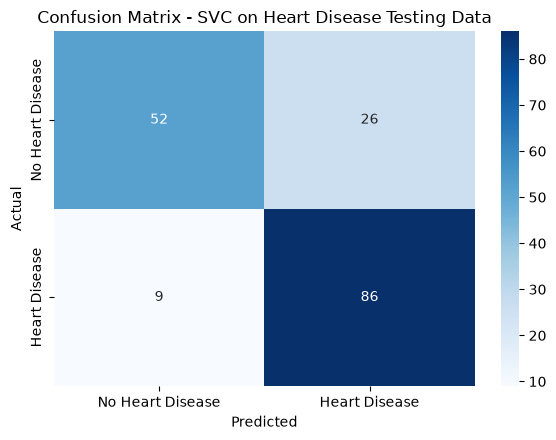

In [17]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, especially in a medical setting where a missed
case and a false alarm have very different costs. This section adds the standard
classification metrics:
- Precision: of everyone the model predicted as "Heart Disease", how many really had it?
- Recall: of everyone who really had heart disease, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Heart Disease", "Actual: Heart Disease"],
    columns=["Predicted: No Heart Disease", "Predicted: Heart Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(6, 4.5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Heart Disease", "Heart Disease"],
            yticklabels=["No Heart Disease", "Heart Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [18]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter their own data
(Age, Gender, ChestPain, ExerciseAngina). In an interactive Jupyter session,
running this cell will prompt you for input(). For this notebook copy,
we pre-fill a demo patient so the notebook can also be read/run
top-to-bottom without needing to type anything.

To try your own values interactively, replace the four lines below with:
    age_input = int(input("Please enter Age in years here (28 to 77): ").strip())
    gender_input = input("Please enter your Gender here (Male, Female): ").strip()
    chestpain_input = input("Please enter Chest pain type here (Typical angina, Atypical angina, Non-anginal pain, Asymptomatic): ").strip()
    exerciseangina_input = input("Please enter Exercise-induced angina here (Yes, No): ").strip()

Age is used as a real number.
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
age_input = 62
gender_input = "Male"
chestpain_input = "Asymptomatic"
exerciseangina_input = "Yes"

print(f"Age: {age_input}, Gender: {gender_input}, ChestPain: {chestpain_input}, ExerciseAngina: {exerciseangina_input}")


Age: 62, Gender: Male, ChestPain: Asymptomatic, ExerciseAngina: Yes


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [19]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's input (entered as text and numbers)
and converts it into a structured feature vector (DataFrame).
"""

user_input = pd.DataFrame({
    "Age": [age_input],
    "Gender": [gender_input],
    "ChestPain": [chestpain_input],
    "ExerciseAngina": [exerciseangina_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)




User Input Feature Vector:

   Age Gender     ChestPain ExerciseAngina
0   62   Male  Asymptomatic            Yes


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [20]:
"""
Purpose of this section:
-------------------------
This part of the code encodes the user's input into numeric values
using the previously trained LabelEncoders. Age is already a number,
so it is kept as it is.
"""

unseen_data_features = user_input.copy()

unseen_data_features["Gender"] = gender_label_encoder.transform(user_input["Gender"])
unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exerciseangina_label_encoder.transform(user_input["ExerciseAngina"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)




User Input Encoded Feature Vector:

   Age  Gender  ChestPain  ExerciseAngina
0   62       1          0               1


### Step 8.4: Load the Saved Model

In [21]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for the Application Phase.
"""

with open("svc_trained_model.pkl", "rb") as model_file:
    model = pickle.load(model_file)

### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [22]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained Support Vector Classifier (SVC)
to predict whether a new patient (user input) has heart disease or not.
"""

predicted_heart_disease = model.predict(unseen_data_features)

if predicted_heart_disease[0] == 1:
    prediction = "HEART DISEASE"
if predicted_heart_disease[0] == 0:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)
print("\nEducational model only - not a medical diagnosis.")

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|         HEART DISEASE          |
+--------------------------------+

Educational model only - not a medical diagnosis.


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [23]:
"""
Purpose of this section:
-------------------------
Step 9.1: Example feedback collected from a domain expert reviewing
this model's predictions on a few real-world-style patient profiles.
The model's prediction and the evidence from the dataset are computed live below
(similar patients = same gender, chest pain type and exercise angina, age within 5 years).
The reviewer names are illustrative; replace them with real reviewers when you have them.
"""

example_profiles = pd.DataFrame({
    "Age": [62, 35, 55, 45],
    "Gender": ["Male", "Female", "Male", "Female"],
    "ChestPain": ["Asymptomatic", "Atypical angina", "Non-anginal pain", "Typical angina"],
    "ExerciseAngina": ["Yes", "No", "No", "Yes"],
})

# Encode the profiles exactly as in Step 8.3 (Age stays a number), then ask the model for a prediction
encoded_profiles = example_profiles.copy()
encoded_profiles["Gender"] = gender_label_encoder.transform(example_profiles["Gender"])
encoded_profiles["ChestPain"] = chestpain_label_encoder.transform(example_profiles["ChestPain"])
encoded_profiles["ExerciseAngina"] = exerciseangina_label_encoder.transform(example_profiles["ExerciseAngina"])
predicted = model.predict(encoded_profiles)

# Compare each prediction with what happened to similar patients in the dataset
feedback = []
for (_, profile), prediction in zip(example_profiles.iterrows(), predicted):
    similar = original_sample_data[
        (original_sample_data["Gender"] == profile["Gender"])
        & (original_sample_data["ChestPain"] == profile["ChestPain"])
        & (original_sample_data["ExerciseAngina"] == profile["ExerciseAngina"])
        & ((original_sample_data["Age"] - profile["Age"]).abs() <= 5)
    ]
    total = len(similar)
    positives = int((similar["HeartDisease"] == "Yes").sum())
    answer = "YES" if prediction == 1 else "NO"
    if total == 0:
        feedback.append(f"No similar patients exist in the dataset, so the data cannot confirm the {answer} prediction.")
    elif total < 10:
        feedback.append(f"Too few similar patients to judge: only {total} exist ({positives} had heart disease). The model says {answer}, but the data cannot confirm it.")
    else:
        share = positives / total
        text = f"{positives} of {total} similar patients ({share:.0%}) had heart disease"
        if abs(share - 0.5) < 0.1:
            feedback.append(f"Borderline: {text}, so the prediction follows a narrow majority and is uncertain.")
        elif (share > 0.5) == (prediction == 1):
            feedback.append(f"Matches the data: {text}.")
        else:
            feedback.append(f"Disagrees with the data: {text}, but the model says {answer}.")

example_profiles["Model Prediction"] = np.where(predicted == 1, "HEART DISEASE", "NO HEART DISEASE")
example_profiles["Reviewer"] = ["Domain Expert (Cardiology)", "Domain Expert (Cardiology)", "Student Tester", "Student Tester"]
example_profiles["Feedback"] = feedback
print(example_profiles.to_string(index=False))


 Age Gender        ChestPain ExerciseAngina Model Prediction                   Reviewer                                                                                                                     Feedback
  62   Male     Asymptomatic            Yes    HEART DISEASE Domain Expert (Cardiology)                                                        Matches the data: 98 of 107 similar patients (92%) had heart disease.
  35 Female  Atypical angina             No NO HEART DISEASE Domain Expert (Cardiology)    Too few similar patients to judge: only 6 exist (0 had heart disease). The model says NO, but the data cannot confirm it.
  55   Male Non-anginal pain             No NO HEART DISEASE             Student Tester Borderline: 18 of 44 similar patients (41%) had heart disease, so the prediction follows a narrow majority and is uncertain.
  45 Female   Typical angina            Yes NO HEART DISEASE             Student Tester                                      No similar patients exi

#### Step 9.2: Make a List of Potential Improvements

In [24]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the feedback above.
"""

improvements = [
    "Add maximum heart rate (thalach) and ST depression (oldpeak): these clinical measurements are left unused by the 4-attribute limit, so check whether they lift accuracy above the current 80%",
    "Impute the 55 missing exercise-angina values instead of dropping those rows, and clean the 172 impossible zeros in cholesterol so that it can be tested as an extra input; check whether the results change",
    "Use cross-validation and report recall for the 'Heart Disease' class separately - in a screening setting a missed case costs more than a false alarm (5-fold accuracy is about 77% to 80% across folds, so the single 80% test result is a fair but slightly noisy estimate)",
    "Check the model separately for women (only 192 of the 865 patients) and for each source hospital, because the disease rate differs a lot between hospitals (36% to 93%)",
    "Compare additional models (e.g. Logistic Regression, Decision Tree, Random Forest) and tune the SVC settings (C and gamma) instead of using the defaults",
    "Report a probability score with each prediction, because many profiles sit close to the 50% line and a plain Yes/No hides that uncertainty",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")


1. Add maximum heart rate (thalach) and ST depression (oldpeak): these clinical measurements are left unused by the 4-attribute limit, so check whether they lift accuracy above the current 80%
2. Impute the 55 missing exercise-angina values instead of dropping those rows, and clean the 172 impossible zeros in cholesterol so that it can be tested as an extra input; check whether the results change
3. Use cross-validation and report recall for the 'Heart Disease' class separately - in a screening setting a missed case costs more than a false alarm (5-fold accuracy is about 77% to 80% across folds, so the single 80% test result is a fair but slightly noisy estimate)
4. Check the model separately for women (only 192 of the 865 patients) and for each source hospital, because the disease rate differs a lot between hospitals (36% to 93%)
5. Compare additional models (e.g. Logistic Regression, Decision Tree, Random Forest) and tune the SVC settings (C and gamma) instead of using the defaults
6

#### Step 9.3: Improve the Model Based on Feedback

In [25]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain on the improvements listed above and re-run Steps 6-7 to confirm
the new model's accuracy and recall improve before replacing the deployed model.
"""

print("Next version: retrain with additional clinical attributes (and properly cleaned cholesterol), evaluate with cross-validation, then re-check recall before replacing svc_trained_model.pkl")

Next version: retrain with additional clinical attributes (and properly cleaned cholesterol), evaluate with cross-validation, then re-check recall before replacing svc_trained_model.pkl


## Step 10: Deploy Your Model as a Public Web App

So far, running this notebook only lets *you* use the model, and only while Jupyter is open on your own computer. This section shows how to turn it into a **live website** anyone can open in a browser - no Python, no Jupyter, nothing installed on their end.

#### Step 10.1: Why Deploy a Model?

A trained model is only useful if people other than you can access it. Deploying it as a small web app is how data scientists share results with non-technical stakeholders (teachers, classmates, clients) who won't run a notebook themselves.

#### Step 10.2: Create a GitHub Account and Repository

1. If you don't have one, sign up for a free account at **https://github.com**.
2. Create a new repository (click the **+** icon top-right -> **New repository**). Give it a name (e.g. `my-heart-disease-app`), keep it **Public**, and click **Create repository**.
3. Upload your project files to this repository. The easiest way from a browser: open your new repo -> **Add file -> Upload files** -> drag in `app.py`, `requirements.txt`, and `svc_trained_model.pkl` (created when you run Step 6.4 of this notebook). Optional extras the app uses if they are present: `heart_disease_combined.csv` (the dataset, used for the "patients from the dataset" switch), `heart_logo.png` and `heart_icon.png`.
   - Alternatively, if you're comfortable with git on the command line:
     ```
     git init
     git add .
     git commit -m "Initial commit"
     git branch -M main
     git remote add origin https://github.com/<your-username>/my-heart-disease-app.git
     git push -u origin main
     ```

#### Step 10.3: Write a Simple Web App

You need a small Python script that loads your saved model and lets a user enter inputs through a web form. **Streamlit** is a beginner-friendly library for this - it turns a plain Python script into a web app with almost no HTML/CSS needed.

A complete, working example is provided with this project as `app.py` - copy it into the same folder as `svc_trained_model.pkl`. It does four things:
1. Loads your trained model with `pickle.load(...)`.
2. Recreates the `LabelEncoder`s the same way the notebook did (fit on the same fixed category lists). Age needs no encoding; the saved Pipeline scales it automatically.
3. Uses Streamlit widgets (`st.selectbox`) to collect Age, Gender, ChestPain and ExerciseAngina from the user (each box offers only the values found in the dataset).
4. Calls `model.predict(...)` on a button click and displays the result.

You also need a `requirements.txt` in the **same folder** as `app.py` listing the packages the *web app* needs (this is a shorter list than the notebook's `requirements.txt`; if you use one file for both, add `streamlit` to it):
```
streamlit
scikit-learn==<the version you trained with>
pandas
numpy
pillow
```

#### Step 10.4: Create a Streamlit Community Cloud Account

1. Go to **https://share.streamlit.io**.
2. Click **Sign up** / **Sign in with GitHub** and authorize Streamlit to access your GitHub repositories. This is free for public apps.

#### Step 10.5: Deploy Your App

1. On the Streamlit Cloud dashboard, click **Create app** -> **Deploy a public app from GitHub**.
2. Fill in:
   - **Repository:** `<your-username>/my-heart-disease-app`
   - **Branch:** `main`
   - **Main file path:** `app.py`
3. Click **Deploy**. The first deploy takes a minute or two while it installs your `requirements.txt`.
4. You'll get a public URL like `https://<something>.streamlit.app` - this is your live app. Share it with anyone!

#### Step 10.6: Troubleshooting Common Issues

Check here first if your app fails:

- **`ModuleNotFoundError` for a package that's clearly in `requirements.txt`:** This usually means the deployment's default Python version doesn't have a prebuilt package ("wheel") for one of your package versions. **Fix:** open your app's **Settings -> General -> Python version** in the Streamlit Cloud dashboard, pick a stable version like **3.11** or **3.12**, then save (it will reboot automatically).
- **`InconsistentVersionWarning` or an error while loading `svc_trained_model.pkl`:** A pickled scikit-learn model is only guaranteed to load in the **same scikit-learn version** that created it. **Fix:** pin the version you trained with in `requirements.txt` (find it with `python -c "import sklearn; print(sklearn.__version__)"`, then add a line such as `scikit-learn==<that version>`), or simply re-run the notebook inside the deployment environment's version and upload the new `.pkl`.
- **App stuck on "Your app is in the oven" for a very long time:** This usually means it's stuck retrying after a crash, not still building normally (a normal build finishes in a few minutes). **Fix:** open the app, click **Manage app** (bottom-right) to see the live build log, check for red error lines, fix the underlying `requirements.txt`/Python version issue, then use the reboot option in that same log panel.
- **`requirements.txt` seems to be ignored:** Make sure it's in the exact same folder as your main app file (`app.py`), not just somewhere in the repo.
- **`FileNotFoundError: svc_trained_model.pkl`:** The `.pkl` file was not uploaded to the repository. Run Step 6.4 of the notebook and upload the file next to `app.py`.

#### Step 10.7: Share Your Live Link

Once deployed, add the link to your notebook, your GitHub repo's `README.md`, or send it directly to whoever you want to try your model - they just click and use it, with nothing to install. Keep the educational disclaimer visible in the app: it must not be presented as a medical diagnosis tool.

---

## Conclusion
The analysis shows that in this dataset the rate of heart disease rises with age, with male gender and with exercise-induced angina, and it depends strongly on chest pain type: for example 74% of patients aged 60 and over had heart disease compared with 33% of those under 45, 63% of men compared with 26% of women, 84% of patients with exercise-induced angina compared with 36% of those without, and 79% of patients with asymptomatic chest pain compared with 14% of those with atypical angina. Using only these four attributes, the Support Vector Classifier achieved an accuracy of 0.80 on the held-out test set of 173 patients (see Step 7.5). It caught 91% of the patients who really had heart disease (recall 0.91, precision 0.77), but it wrongly flagged 26 of the 78 healthy patients (recall 0.67 for the No Heart Disease class), so it leans towards predicting disease. This is an improvement over the version that used cholesterol instead of exercise-induced angina (about 0.74 on the same kind of split), because exercise angina separates the two groups much more strongly than cholesterol and also removes far fewer rows during cleaning. It is still a teaching model, not a diagnostic tool; adding stronger clinical measurements (Step 9.2) is the clearest way to improve it.